# Комп'ютерний практикум № 1

**Тема роботи:** дослідження дискретних марковських процесів прийняття рішень та оцінювання заданих політик.

**Мета роботи:** навчитися описувати дискретний MDP, будувати матрицю ймовірностей переходів для заданої політики, досліджувати розподіли станів і обчислювати функцію цінності; порівняти результати розрахунків із результатами моделювання траєкторій агента.

**Зміст**

* **Частина I.** Середовище *FrozenLake* (Gymnasium) з власною картою $6\times6$ — завдання 1–7.
* **Частина II.** Власне MDP «Сходження на вершину» (епізодичне, 3 нетермінальні + 2 термінальні стани, 3 дії) — завдання 1–7.
* Додаток: короткі відповіді на контрольні запитання.

Для роботи потрібні файли `fdrl26_rl.py`, `fdrl26_fl.py` (надані у демо) та `mdp26.py` (наданий клас `MDP`, винесений в окремий модуль, щоб використовувати його і в наступних практикумах).

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import sys; sys.path.append("..")
from utils import fdrl26_fl as fl   # функції для FrozenLake
from utils import fdrl26_rl as rl   # класичні функції RL
from utils.mdp26 import MDP    # наданий клас MDP

np.set_printoptions(precision=4, suppress=True, linewidth=120)
SEED = 2026
np.random.seed(SEED)     # rl.agent використовує глобальний генератор numpy

---
# Частина I. Середовище *FrozenLake*

## Завдання 1. Власна карта, середовище, ліміт епізоду

Карта $N\times N$ з $N=6$ (36 станів). Старт `S` — стан 0 (лівий верхній кут), ціль `G` — стан 35 (правий нижній кут), **5 ополонок** `H`: стани 7, 10, 20, 24, 29. Ополонки розміщено так, щоб прямолінійний рух уздовж країв і по діагоналі був ризикованим: ополонка 29 стоїть безпосередньо над ціллю, а 24 — у лівому стовпці.

Параметри: `is_slippery=True`, ліміт епізоду $H=60$ кроків, коефіцієнт дисконтування $\gamma=0.95$ (використовується в завданнях 4 і 6).

In [2]:
FL_map = ['SFFFFF',
          'FHFFHF',
          'FFFFFF',
          'FFHFFF',
          'HFFFFH',
          'FFFFFG']

H_FL  = 60      # ліміт кроків епізоду
GAMMA = 0.95    # коефіцієнт дисконтування

env = gym.make("FrozenLake-v1", is_slippery=True, desc=FL_map,
               max_episode_steps=H_FL, render_mode="rgb_array")

N  = len(FL_map)
nS = env.observation_space.n
nA = env.action_space.n
P  = env.unwrapped.P

flat   = ''.join(FL_map)
holes  = [s for s, ch in enumerate(flat) if ch == 'H']
goal   = flat.index('G')
start  = flat.index('S')
terminals = holes + [goal]
action_arrows = {0: '←', 1: '↓', 2: '→', 3: '↑'}
print(f"N={N}, nS={nS}, nA={nA}; старт={start}, ціль={goal}, ополонки={holes}")

N=6, nS=36, nA=4; старт=0, ціль=35, ополонки=[7, 10, 20, 24, 29]


Перевіримо, що від старту до цілі існує маршрут (пошук у ширину по клітинках, які не є ополонками).

In [3]:
from collections import deque

def path_exists(desc):
    n = len(desc); f = ''.join(desc)
    seen, q = {0}, deque([0])
    while q:
        s = q.popleft(); r, c = divmod(s, n)
        for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            rr, cc = r + dr, c + dc
            if 0 <= rr < n and 0 <= cc < n:
                t = rr * n + cc
                if t not in seen and f[t] != 'H':
                    seen.add(t); q.append(t)
    return f.index('G') in seen

print("Маршрут від S до G існує:", path_exists(FL_map))

Маршрут від S до G існує: True


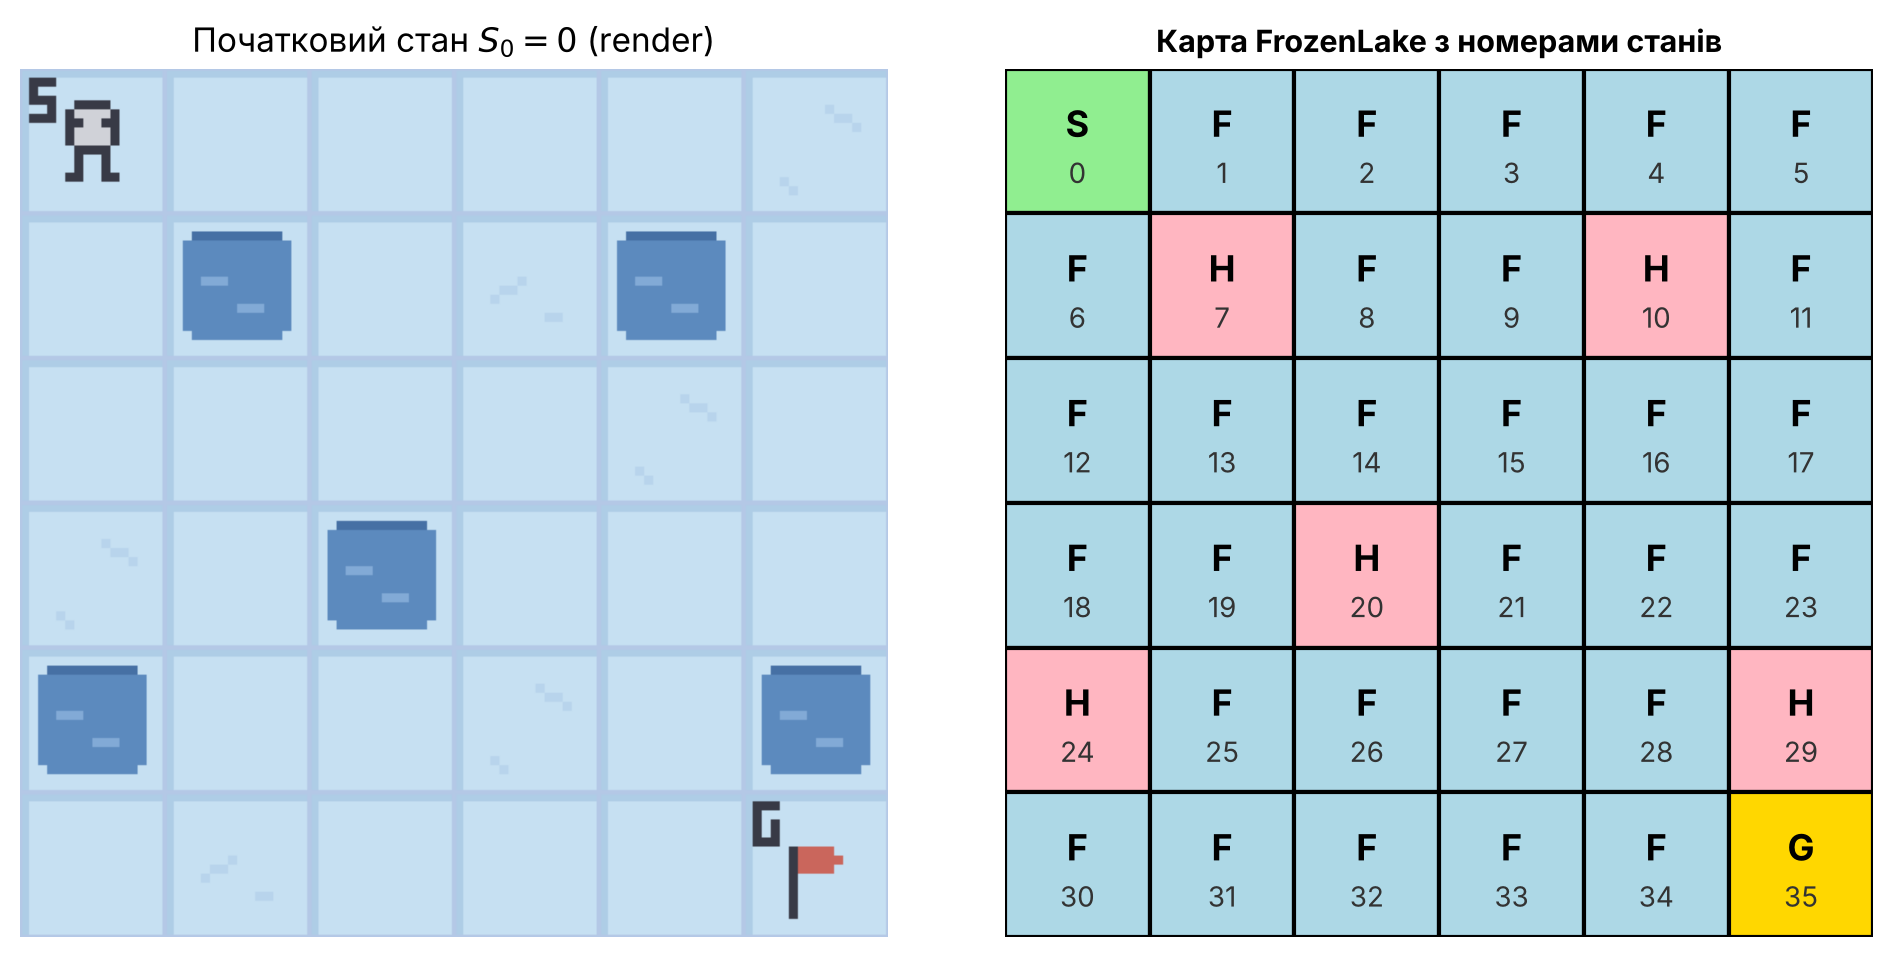

In [4]:
def plot_map_with_states(desc, title="Карта FrozenLake з номерами станів", ax=None):
    n = len(desc)
    colors = {'S': '#90EE90', 'F': '#ADD8E6', 'H': '#FFB6C1', 'G': '#FFD700'}
    if ax is None:
        fig, ax = plt.subplots(figsize=(4.6, 4.6))
    for i in range(n):
        for j in range(n):
            s, ch = i * n + j, desc[i][j]
            ax.add_patch(plt.Rectangle((j, n - 1 - i), 1, 1, facecolor=colors[ch], edgecolor='k', lw=1.5))
            ax.text(j + 0.5, n - 1 - i + 0.62, ch, ha='center', va='center', fontsize=13, fontweight='bold')
            ax.text(j + 0.5, n - 1 - i + 0.28, str(s), ha='center', va='center', fontsize=10, color='#333')
    ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=11, fontweight='bold')
    return ax

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
state, info = env.reset(seed=SEED)
axes[0].imshow(env.render()); axes[0].axis('off'); axes[0].set_title("Початковий стан $S_0=0$ (render)")
plot_map_with_states(FL_map, ax=axes[1])
plt.tight_layout(); plt.savefig("FL_map.png", bbox_inches="tight", dpi=120); plt.show()

Стани нумеруються за рядками: $s = 6\cdot\text{рядок} + \text{стовпець}$. Дії: `0` — ←, `1` — ↓, `2` — →, `3` — ↑.

## Завдання 2. Правила переходів

Модель переходів зберігається у словнику `P[s][a] = [(p, s', r, done), ...]`. Подивимося на кілька характерних пар $(s,a)$.

In [5]:
def show_transitions(s, a):
    print(f"s={s} ({flat[s]}), a={a} ({action_arrows[a]}):")
    for p, s2, r, d in P[s][a]:
        r2, c2 = divmod(s2, N)
        print(f"   p={p:.3f} -> s'={s2:2d} ({flat[s2]}), r={r}, done={d}")

show_transitions(14, 1)   # клітинка в середині: ↓
show_transitions(1, 1)    # над ополонкою 7: ↓
show_transitions(0, 0)    # кут: ← (стінка)
show_transitions(34, 2)   # поруч із ціллю: →
show_transitions(7, 2)    # термінальний стан (ополонка)

s=14 (F), a=1 (↓):
   p=0.333 -> s'=13 (F), r=0, done=False
   p=0.333 -> s'=20 (H), r=0, done=True
   p=0.333 -> s'=15 (F), r=0, done=False
s=1 (F), a=1 (↓):
   p=0.333 -> s'= 0 (S), r=0, done=False
   p=0.333 -> s'= 7 (H), r=0, done=True
   p=0.333 -> s'= 2 (F), r=0, done=False
s=0 (S), a=0 (←):
   p=0.333 -> s'= 0 (S), r=0, done=False
   p=0.333 -> s'= 0 (S), r=0, done=False
   p=0.333 -> s'= 6 (F), r=0, done=False
s=34 (F), a=2 (→):
   p=0.333 -> s'=34 (F), r=0, done=False
   p=0.333 -> s'=35 (G), r=1, done=True
   p=0.333 -> s'=28 (F), r=0, done=False
s=7 (H), a=2 (→):
   p=1.000 -> s'= 7 (H), r=0, done=True


In [6]:
# Перевіримо загальне правило для всіх нетермінальних станів:
# фактичний напрямок руху ∈ {a-1, a, a+1} (mod 4), кожен з імовірністю 1/3; протилежний напрямок неможливий.
moves = {0: (0, -1), 1: (1, 0), 2: (0, 1), 3: (-1, 0)}
def target(s, d):
    r, c = divmod(s, N); dr, dc = moves[d]
    return min(max(r + dr, 0), N - 1) * N + min(max(c + dc, 0), N - 1)

ok = True
for s in range(nS):
    if s in terminals: continue
    for a in range(nA):
        expected = Counter()
        for d in [(a - 1) % 4, a, (a + 1) % 4]:
            expected[target(s, d)] += 1 / 3
        got = Counter()
        for p, s2, r, done in P[s][a]:
            got[s2] += p
        ok &= all(np.isclose(got[k], expected[k]) for k in set(got) | set(expected))
print("Правило 'вибраний напрямок або один із двох перпендикулярних, по 1/3' виконується для всіх (s,a):", ok)
print("Сума ймовірностей для кожної пари (s,a) = 1:",
      all(np.isclose(sum(p for p, *_ in P[s][a]), 1) for s in range(nS) for a in range(nA)))

Правило 'вибраний напрямок або один із двох перпендикулярних, по 1/3' виконується для всіх (s,a): True
Сума ймовірностей для кожної пари (s,a) = 1: True


**Пояснення.** За `is_slippery=True` лід «слизький»: вибрана дія задає лише *намір*. Середовище з імовірністю $1/3$ переміщує агента у вибраному напрямку і з імовірністю $1/3$ — у кожен із двох **перпендикулярних** напрямків (для ↓ це ← і →). Рух у протилежному напрямку неможливий. Якщо перехід веде за межі карти, агент залишається на місці (приклад зі станом 0: дія ← дає $p=2/3$ залишитися в стані 0). Тому дія ↓ у стані 1 з імовірністю $1/3$ приводить в ополонку 7, хоча агент «хотів» лише обійти її — так виникає стохастичність переходів, яка не залежить від агента.

Винагорода $+1$ нараховується лише за перехід у ціль, решта переходів дає $0$. Ціль та ополонки — термінальні: у моделі `P` для них усі дії дають $(1.0, s, 0, \text{True})$, тобто це поглинальні стани.

## Завдання 3. Політики

* $\pi_1$ — рівноймовірний вибір дій: $\pi_1(a\mid s)=1/4$.
* $\pi_2$ — власна детермінована політика. Принцип побудови: **у кожному стані вибираємо дію, жоден із трьох можливих результатів якої не веде в ополонку**, а серед таких — ту, що найчастіше зсуває агента до цілі. Наприклад, у стані 1 (над ополонкою 7) дія ↑ дає «залишитися / ← / →» і тому безпечна, а ↓ — ні; у стані 34 дія → дає «ціль / ↑ / залишитися».

[[1 3 2 2 3 1]
 [0 0 2 0 0 2]
 [1 1 3 1 1 1]
 [3 0 0 2 1 3]
 [0 2 1 1 0 0]
 [1 2 2 2 2 0]]


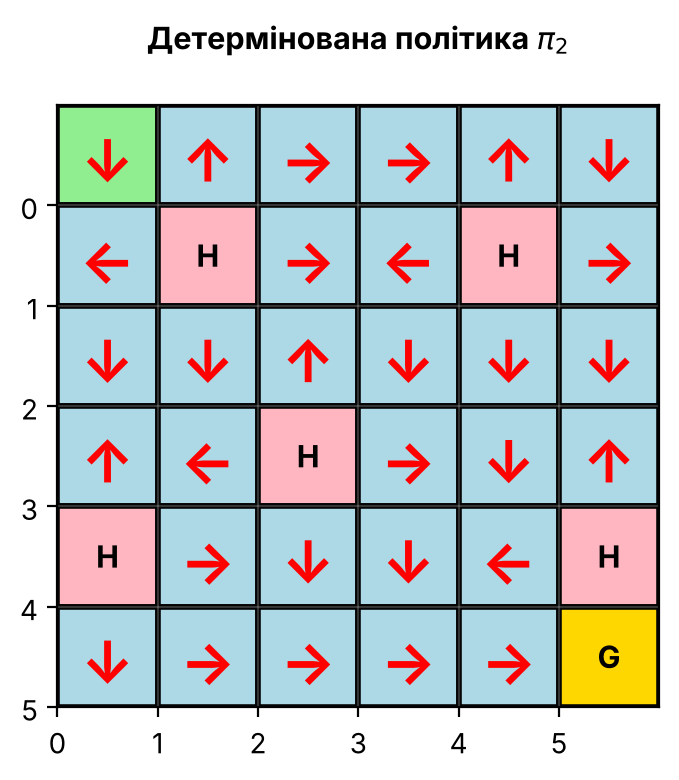

In [7]:
# 0(← L), 1(↓ D), 2(→ R), 3(↑ U), '.'/'0' — термінальні стани (дія не має значення)
policy2_symbolic = ['↓ ↑ → → ↑ ↓',
                    '← . → ← . →',
                    '↓ ↓ ↑ ↓ ↓ ↓',
                    '↑ ← . → ↓ ↑',
                    '. → ↓ ↓ ← .',
                    '↓ → → → → 0']

policy2_det = fl.policy_symbolic_to_deterministic(policy2_symbolic)
policy1 = rl.policy_deterministic_to_stochastic(policy2_det, nA, epsilon=1.0)   # рівноймовірна
policy2 = rl.policy_deterministic_to_stochastic(policy2_det, nA, epsilon=0.0)   # детермінована

print(policy2_det.reshape(N, N))
fl.plot_deterministic_policy(policy2_det, FL_map, title="Детермінована політика $\\pi_2$")

In [8]:
# Перевірка властивості «безпечності» π2: жоден можливий наступний стан не є ополонкою
risky = [(s, s2) for s in range(nS) if s not in terminals
         for p, s2, r, d in P[s][policy2_det[s]] if s2 in holes and p > 0]
print("Переходи в ополонку за π2 за один крок:", risky if risky else "немає")

# Для порівняння: частка (s,a), що можуть привести в ополонку, серед усіх дій (їх використовує π1)
n_risky = sum(any(s2 in holes for p, s2, r, d in P[s][a]) for s in range(nS) if s not in terminals for a in range(nA))
print(f"Ризикованих пар (s,a) серед усіх: {n_risky} з {(nS - len(terminals)) * nA}")

Переходи в ополонку за π2 за один крок: немає
Ризикованих пар (s,a) серед усіх: 51 з 120


Ціль досяжна з початкового стану за $\pi_2$: наприклад, траєкторія $0\xrightarrow{↓}6\to12\to18\to\dots$ (детальніше — ймовірності в завданні 5). Політика не обов'язково оптимальна: вона уникає ризику, але через це рухається повільно (часто «ковзає» вбік або залишається на місці).

## Завдання 4. Моделювання серій епізодів

Для кожної політики проводимо $10\,000$ епізодів з однаковим лімітом $H=60$ кроків (ліміт задано і в середовищі `max_episode_steps`, і в `run_episode`). Для кожного епізоду фіксуємо результат (ціль / ополонка / ліміт кроків), дисконтований дохід $G_0=\sum_{t=0}^{T-1}\gamma^t R_{t+1}$ і стан агента на кроках $k\in\{1,2,3,5,10,20,40,60\}$ — це знадобиться в завданні 5 для порівняння з розподілами $\mu_k$.

In [9]:
N_EPISODES = 10_000
CHECK_STEPS = [1, 2, 3, 5, 10, 20, 40, 60]

def simulate(env, policy, gamma, n_episodes, max_steps, check_steps, outcome_fn, n_states):
    '''Серія епізодів з використанням rl.run_episode.
    Повертає масиви доходів, довжин, результатів та емпіричні розподіли станів на кроках check_steps.
    Після термінального стану агент вважається таким, що залишається в ньому (поглинальний стан).'''
    returns, lengths, outcomes = [], [], []
    counts = {k: np.zeros(n_states) for k in check_steps}
    for _ in range(n_episodes):
        G0, steps, traj = rl.run_episode(env, policy, gamma, max_steps=max_steps)
        returns.append(G0); lengths.append(steps); outcomes.append(outcome_fn(traj))
        for k in check_steps:
            if k <= len(traj):
                counts[k][traj[k - 1][3]] += 1
            elif traj[-1][4]:                 # епізод завершився раніше в термінальному стані
                counts[k][traj[-1][3]] += 1
    mu_hat = {k: counts[k] / counts[k].sum() for k in check_steps}
    return np.array(returns), np.array(lengths), np.array(outcomes), mu_hat

def fl_outcome(traj):
    s_last, term, trunc = traj[-1][3], traj[-1][4], traj[-1][5]
    if term:
        return 'goal' if s_last == goal else 'hole'
    return 'limit'

env.reset(seed=SEED)
sim = {}
for name, pol in [('π1', policy1), ('π2', policy2)]:
    sim[name] = simulate(env, pol, GAMMA, N_EPISODES, H_FL, CHECK_STEPS, fl_outcome, nS)

In [10]:
def ci(p, n):                       # 95% довірчий інтервал для частки
    return 1.96 * np.sqrt(p * (1 - p) / n)

print(f"{'':4}| {'ціль':>16} | {'ополонка':>16} | {'ліміт кроків':>16} | {'середній G0':>20} | сер. довжина")
print("-" * 100)
for name in sim:
    G, L, O, _ = sim[name]
    fr = {k: np.mean(O == k) for k in ['goal', 'hole', 'limit']}
    se = 1.96 * G.std(ddof=1) / np.sqrt(len(G))
    print(f"{name:4}| " + " | ".join(f"{fr[k]:.4f} ± {ci(fr[k], len(O)):.4f}" for k in ['goal', 'hole', 'limit'])
          + f" | {G.mean():.5f} ± {se:.5f} | {L.mean():6.2f}")

    |             ціль |         ополонка |     ліміт кроків |          середній G0 | сер. довжина
----------------------------------------------------------------------------------------------------
π1  | 0.0034 ± 0.0011 | 0.9960 ± 0.0012 | 0.0006 ± 0.0005 | 0.00122 ± 0.00043 |   9.10
π2  | 0.5238 ± 0.0098 | 0.0000 ± 0.0000 | 0.4762 ± 0.0098 | 0.09228 ± 0.00236 |  48.83


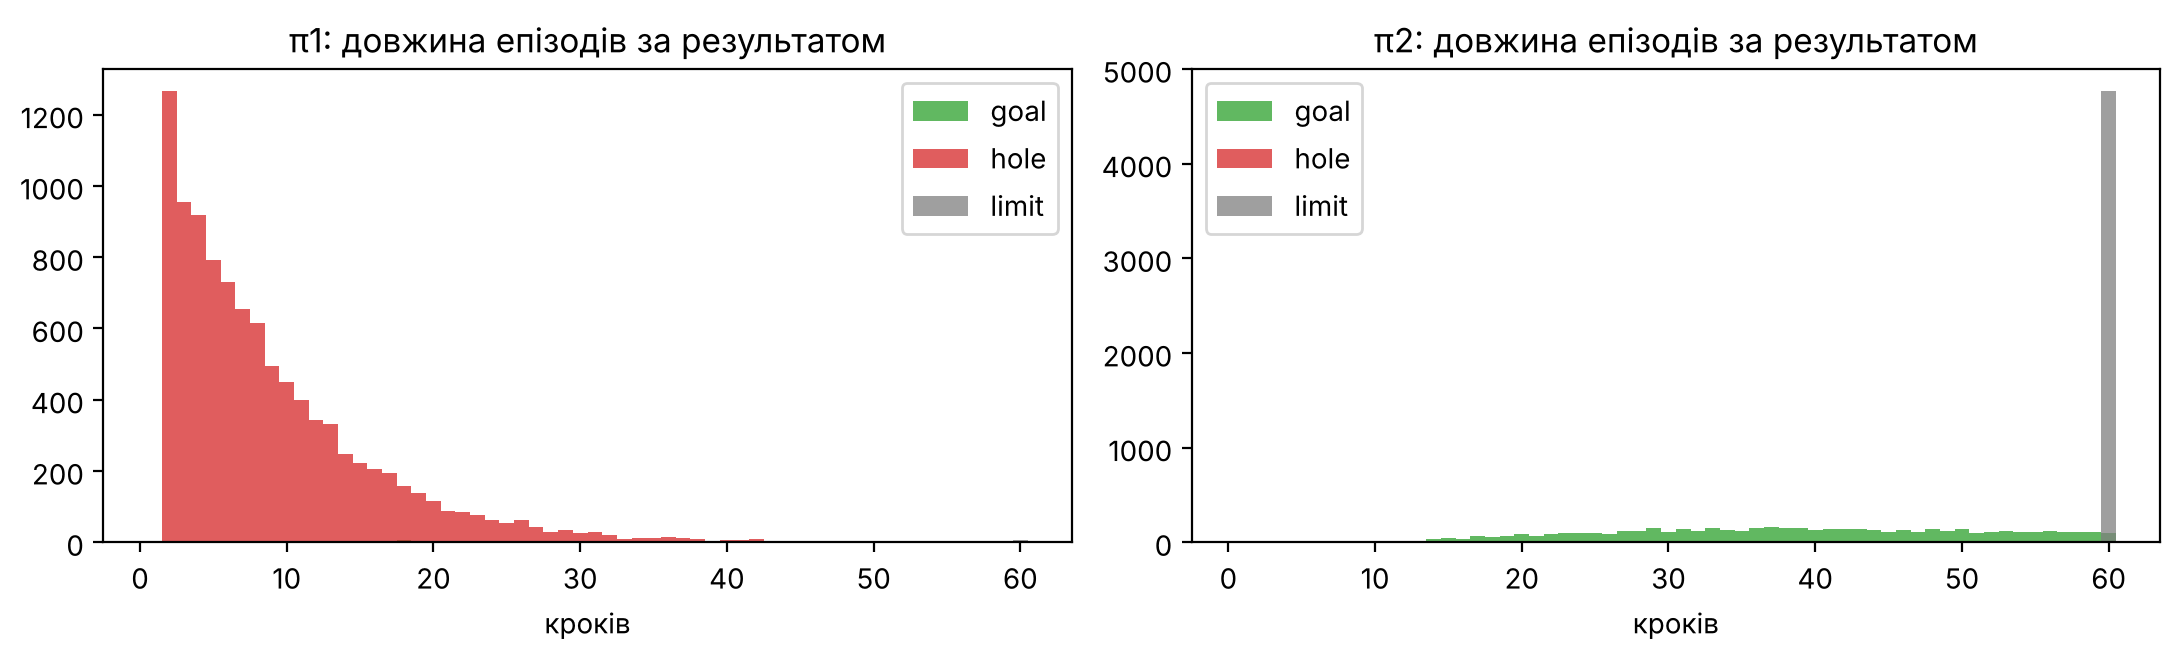

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, name in zip(axes, sim):
    G, L, O, _ = sim[name]
    for k, c in [('goal', '#2ca02c'), ('hole', '#d62728'), ('limit', '#7f7f7f')]:
        ax.hist(L[O == k], bins=np.arange(0.5, H_FL + 1.5), color=c, alpha=0.75, label=k)
    ax.set_title(f"{name}: довжина епізодів за результатом"); ax.set_xlabel("кроків"); ax.legend()
plt.tight_layout(); plt.show()

## Завдання 5. Матриці переходів $T^\pi$ і розподіли станів

Після фіксації політики система «середовище + агент» — це ланцюг Маркова з матрицею

$$T^\pi_{ss'}=\sum_a\pi(a\mid s)\,p(s'\mid s,a),\qquad \mu_{k}=\mu_0\,(T^\pi)^k,\quad \mu_0=e_{s_0}.$$

Ціль і ополонки в $T^\pi$ — поглинальні стани ($T^\pi_{ss}=1$), тому $\mu_k(G)$ — це ймовірність досягти цілі **протягом перших $k$ кроків**, а $\sum_{h\in H}\mu_k(h)$ — імовірність провалитися в ополонку протягом $k$ кроків. Ліміт $H$ у матрицю не входить: він не є властивістю переходів, а лише обриває моделювання; його враховуємо, беручи $\mu_H$.

In [12]:
T1 = rl.compute_transition_matrix(P, policy1)
T2 = rl.compute_transition_matrix(P, policy2)
print("T1 коректна:", rl.validate_transition_matrix(T1), "| T2 коректна:", rl.validate_transition_matrix(T2))
row = lambda T, s: {int(j): round(float(T[s, j]), 4) for j in np.nonzero(T[s])[0]}
print("Рядок T1 для стану 0:", row(T1, 0))
print("Рядок T2 для стану 0:", row(T2, 0))
print("Рядок T2 для ополонки 7:", row(T2, 7))

mu0 = np.zeros(nS); mu0[start] = 1.0

def distributions(T, mu0, K):
    mus = [mu0]
    for _ in range(K):
        mus.append(mus[-1] @ T)
    return np.array(mus)            # mus[k] = μ_k

MU = {'π1': distributions(T1, mu0, H_FL), 'π2': distributions(T2, mu0, H_FL)}

T1 коректна: True | T2 коректна: True
Рядок T1 для стану 0: {0: 0.5, 1: 0.25, 6: 0.25}
Рядок T2 для стану 0: {0: 0.3333, 1: 0.3333, 6: 0.3333}
Рядок T2 для ополонки 7: {7: 1.0}


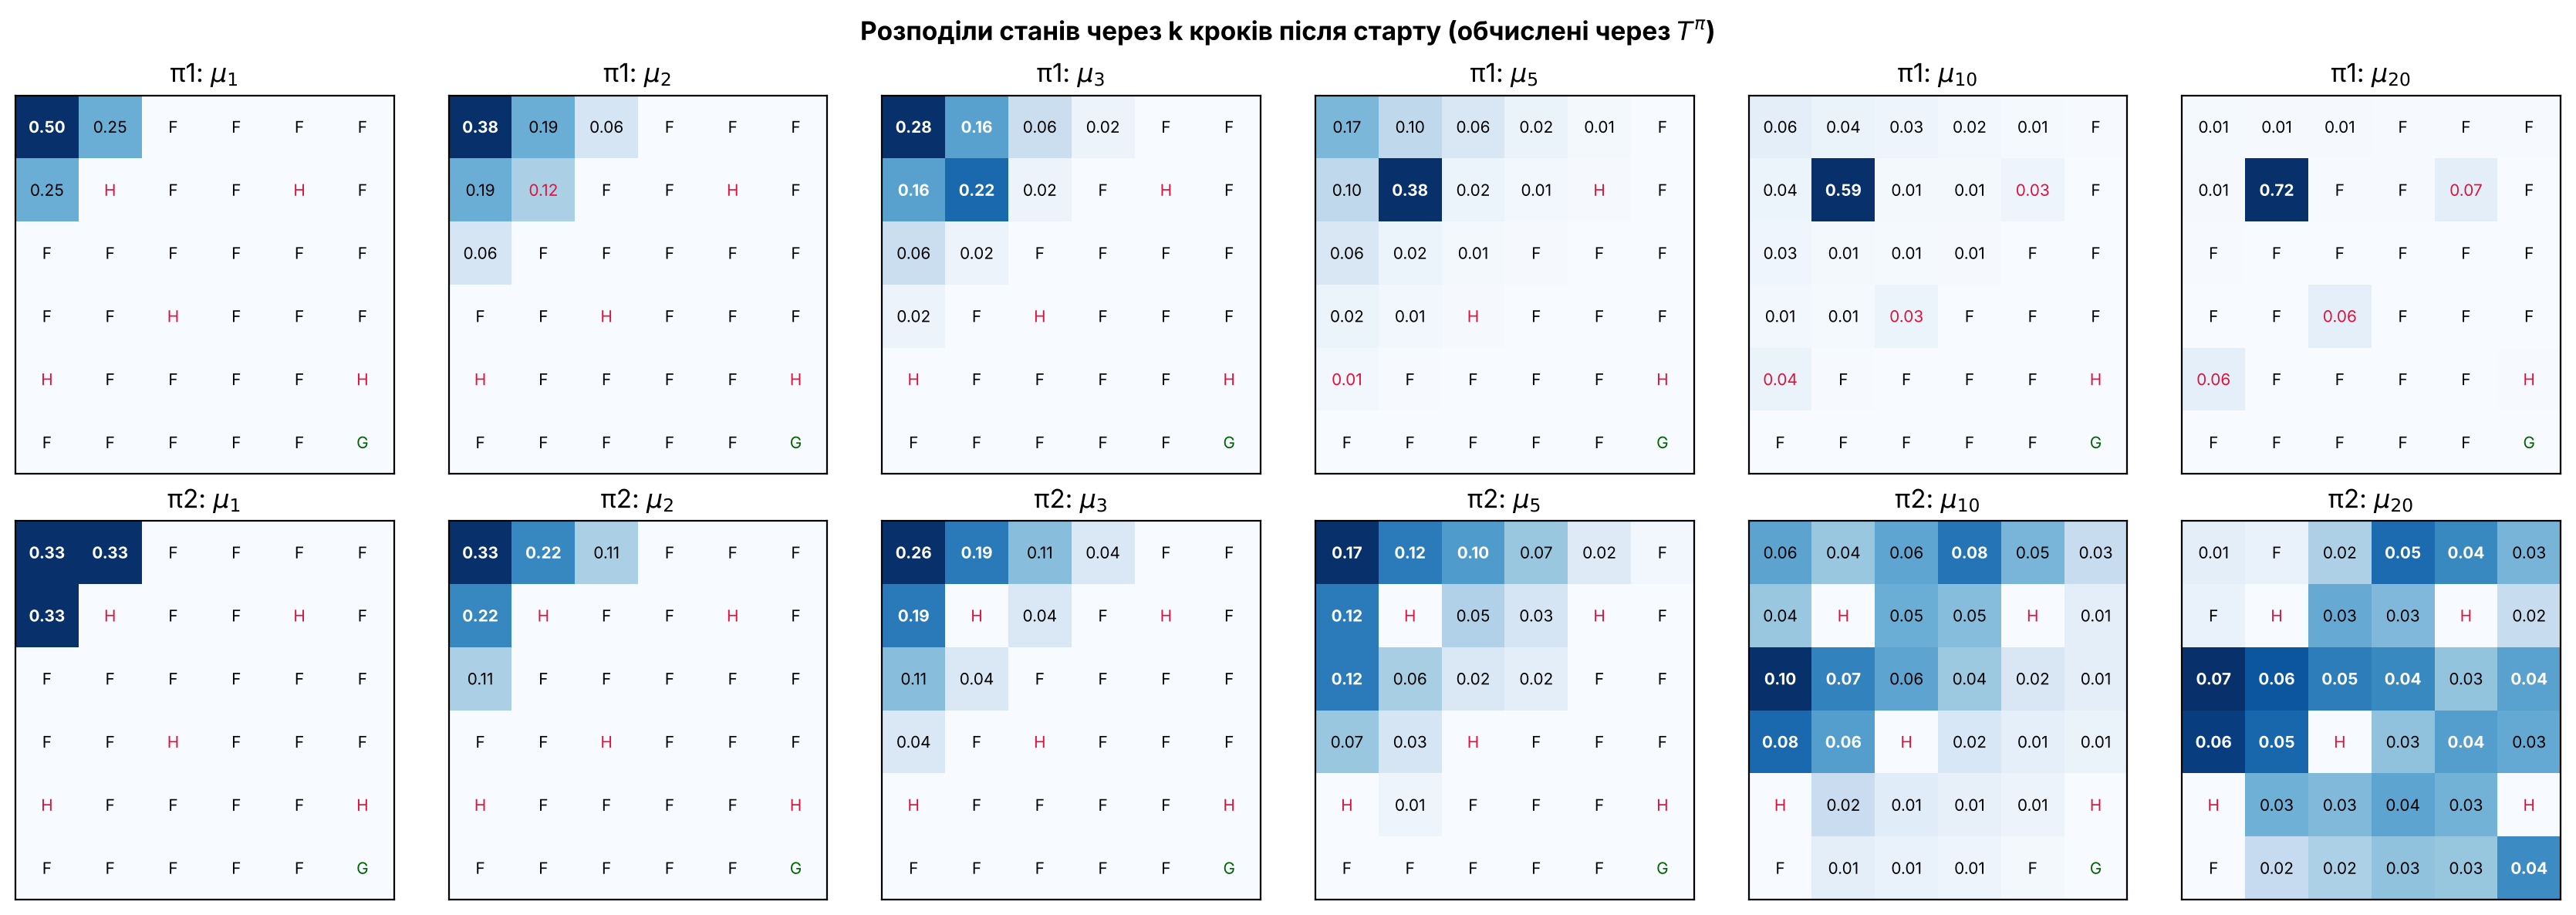

In [13]:
show_k = [1, 2, 3, 5, 10, 20]
fig, axes = plt.subplots(2, len(show_k), figsize=(17, 6))
for row, name in enumerate(MU):
    for col, k in enumerate(show_k):
        ax = axes[row, col]
        M = MU[name][k].reshape(N, N)
        ax.imshow(M, cmap='Blues', vmin=0, vmax=max(M.max(), 1e-9))
        for i in range(N):
            for j in range(N):
                v = M[i, j]
                txt = FL_map[i][j] if v < 0.005 else f"{v:.2f}"
                dark = v > 0.55 * M.max()
                ax.text(j, i, txt, ha='center', va='center', fontsize=7.5, fontweight='bold' if dark else 'normal',
                        color='white' if dark else ('crimson' if FL_map[i][j] == 'H' else ('darkgreen' if FL_map[i][j] == 'G' else 'k')))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{name}: $\\mu_{{{k}}}$")
plt.suptitle("Розподіли станів через k кроків після старту (обчислені через $T^\\pi$)", fontweight='bold')
plt.tight_layout(h_pad=2.0); plt.show()

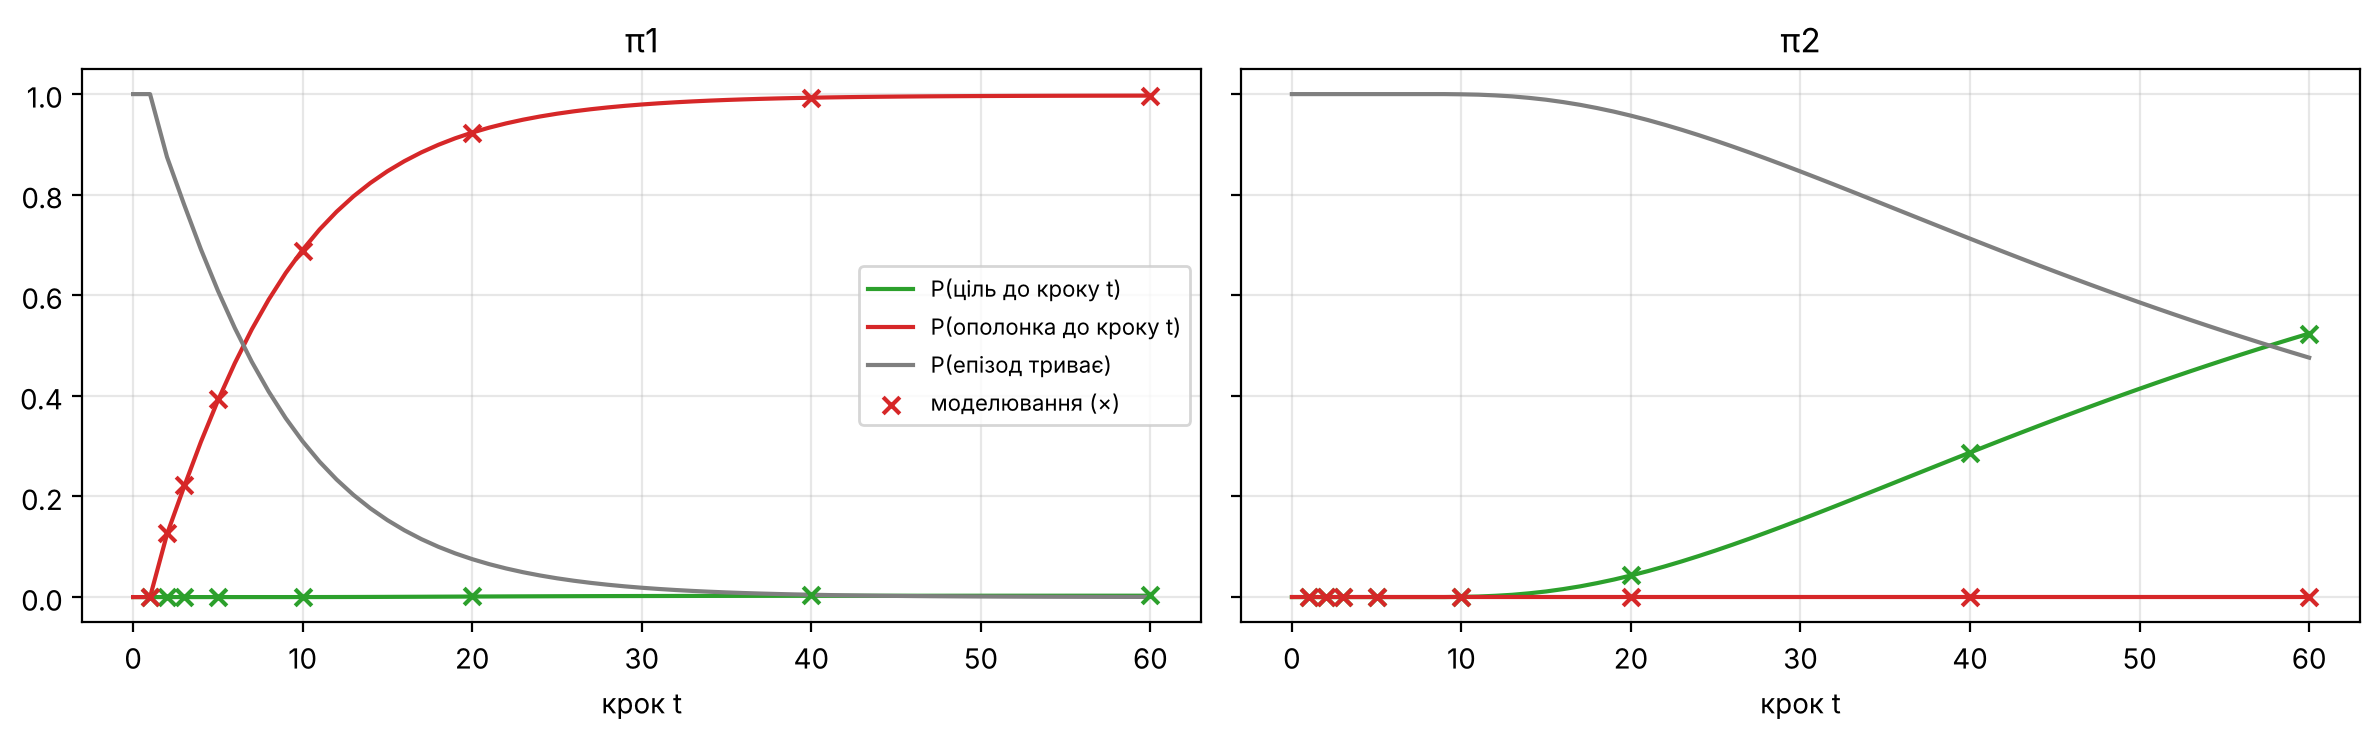

In [14]:
def summary_at(mu):
    return mu[goal], mu[holes].sum(), 1 - mu[goal] - mu[holes].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
t = np.arange(H_FL + 1)
for ax, name in zip(axes, MU):
    pg = MU[name][:, goal]; ph = MU[name][:, holes].sum(1)
    ax.plot(t, pg, color='#2ca02c', label='P(ціль до кроку t)')
    ax.plot(t, ph, color='#d62728', label='P(ополонка до кроку t)')
    ax.plot(t, 1 - pg - ph, color='#7f7f7f', label='P(епізод триває)')
    mu_hat = sim[name][3]
    ax.scatter(CHECK_STEPS, [mu_hat[k][goal] for k in CHECK_STEPS], color='#2ca02c', marker='x', zorder=3)
    ax.scatter(CHECK_STEPS, [mu_hat[k][holes].sum() for k in CHECK_STEPS], color='#d62728', marker='x', zorder=3,
               label='моделювання (×)')
    ax.set_title(name); ax.set_xlabel("крок t"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [15]:
print(f"Порівняння розрахунку (μ_k) і моделювання (частки) на кроці k, {N_EPISODES} епізодів\n")
print(f"{'':3} {'k':>3} | {'P(ціль) розрах.':>15} {'моделюв.':>9} | {'P(ополонка) розрах.':>19} {'моделюв.':>9} | max|μ̂_k − μ_k|")
for name in MU:
    mu_hat = sim[name][3]
    for k in CHECK_STEPS:
        g_, h_, _ = summary_at(MU[name][k]); gh, hh, _ = summary_at(mu_hat[k])
        print(f"{name:3} {k:>3} | {g_:15.4f} {gh:9.4f} | {h_:19.4f} {hh:9.4f} | {np.abs(mu_hat[k] - MU[name][k]).max():.4f}")
    print()

print(f"Ймовірності за H = {H_FL} кроків (розрахунок) vs частки результатів епізодів:")
for name in MU:
    O = sim[name][2]
    g_, h_, l_ = summary_at(MU[name][H_FL])
    print(f"  {name}: ціль {g_:.4f} vs {np.mean(O=='goal'):.4f};  ополонка {h_:.4f} vs {np.mean(O=='hole'):.4f};"
          f"  ліміт {l_:.4f} vs {np.mean(O=='limit'):.4f}")

Порівняння розрахунку (μ_k) і моделювання (частки) на кроці k, 10000 епізодів

      k | P(ціль) розрах.  моделюв. | P(ополонка) розрах.  моделюв. | max|μ̂_k − μ_k|
π1    1 |          0.0000    0.0000 |              0.0000    0.0000 | 0.0045
π1    2 |          0.0000    0.0000 |              0.1250    0.1265 | 0.0045
π1    3 |          0.0000    0.0000 |              0.2188    0.2220 | 0.0084
π1    5 |          0.0000    0.0000 |              0.3906    0.3929 | 0.0067
π1   10 |          0.0000    0.0000 |              0.6904    0.6874 | 0.0036
π1   20 |          0.0011    0.0016 |              0.9235    0.9231 | 0.0035
π1   40 |          0.0025    0.0034 |              0.9928    0.9917 | 0.0042
π1   60 |          0.0027    0.0034 |              0.9970    0.9960 | 0.0041

π2    1 |          0.0000    0.0000 |              0.0000    0.0000 | 0.0099
π2    2 |          0.0000    0.0000 |              0.0000    0.0000 | 0.0074
π2    3 |          0.0000    0.0000 |              0.0000    0.0

**Довгострокова поведінка (без ліміту кроків).** У FrozenLake кожен термінальний стан утворює окремий замкнений клас, тому стаціонарний розподіл **не єдиний**: стаціонарним є будь-який розподіл, зосереджений на термінальних станах. До якого саме з них збігається $\mu_k$, залежить від стартового стану. Граничні ймовірності поглинання з $s_0$ знайдемо двома способами: ітеруванням `evolve_distribution` і через фундаментальну матрицю $B=(I-Q)^{-1}R$, де $Q$ — блок переходів між нетермінальними станами, $R$ — з нетермінальних у термінальні.

In [16]:
transient = [s for s in range(nS) if s not in terminals]
for name, T in [('π1', T1), ('π2', T2)]:
    mu_lim, n_it = rl.evolve_distribution(mu0, T, theta=1e-12, max_iter=20_000)
    Q = T[np.ix_(transient, transient)]; R = T[np.ix_(transient, terminals)]
    B = np.linalg.solve(np.eye(len(transient)) - Q, R)
    tau = np.linalg.solve(np.eye(len(transient)) - Q, np.ones(len(transient)))   # очікувана к-сть кроків до поглинання
    i0 = transient.index(start)
    print(f"{name}: ітерацій {n_it:5d}; P(ціль)={mu_lim[goal]:.4f} (B: {B[i0, -1]:.4f}), "
          f"P(ополонка)={mu_lim[holes].sum():.4f} (B: {B[i0, :-1].sum():.4f}); "
          f"E[кроків до завершення] = {tau[i0]:.1f}")
    print("     розподіл по ополонках", {h: round(float(mu_lim[h]), 4) for h in holes})

π1: ітерацій   179; P(ціль)=0.0027 (B: 0.0027), P(ополонка)=0.9973 (B: 0.9973); E[кроків до завершення] = 9.1
     розподіл по ополонках {7: 0.7544, 10: 0.087, 20: 0.0759, 24: 0.0716, 29: 0.0084}
π2: ітерацій  1122; P(ціль)=1.0000 (B: 1.0000), P(ополонка)=0.0000 (B: 0.0000); E[кроків до завершення] = 71.0
     розподіл по ополонках {7: 0.0, 10: 0.0, 20: 0.0, 24: 0.0, 29: 0.0}


## Завдання 6. Цінність початкового стану $v_\pi(s_0)$

Рівняння Беллмана для заданої політики: $\mathbf v_\pi=\mathbf r_\pi+\gamma T^\pi\mathbf v_\pi$, звідки $\mathbf v_\pi=(I-\gamma T^\pi)^{-1}\mathbf r_\pi$. Розв'яжемо його матрично і перевіримо ітераційним методом `policy_evaluation`.

In [17]:
V = {}
for name, pol, T in [('π1', policy1, T1), ('π2', policy2, T2)]:
    r_pi = rl.compute_policy_reward_vector(P, pol)
    v = np.linalg.solve(np.eye(nS) - GAMMA * T, r_pi)
    v_it, n_it = rl.policy_evaluation(P, pol, GAMMA, theta=1e-10)
    V[name] = (v, r_pi)
    print(f"{name}: v(s0) = {v[start]:.6f}; ітераційно: {v_it[start]:.6f} ({n_it} ітерацій), "
          f"max|v_iter − v_matrix| = {np.abs(v_it - v).max():.2e}")
    fl.print_value_map(v, FL_map)

π1: v(s0) = 0.000896; ітераційно: 0.000896 (102 ітерацій), max|v_iter − v_matrix| = 4.14e-10
0.00090  0.00097  0.00223  0.00302  0.00200  0.00340  
   S        F        F        F        F        F     

0.00101  -0.00000  0.00316  0.00548  0.00000  0.00552  
   F        H        F        F        H        F     

0.00233  0.00356  0.00560  0.01687  0.01977  0.01432  
   F        F        F        F        F        F     

0.00293  0.00706  -0.00000  0.04019  0.05206  0.02068  
   F        F        H        F        F        F     

0.00000  0.02325  0.05034  0.10027  0.13858  0.00000  
   H        F        F        F        F        H     

0.01832  0.04049  0.08843  0.19307  0.43117  0.00000  
   F        F        F        F        F        G     

π2: v(s0) = 0.099938; ітераційно: 0.099938 (272 ітерацій), max|v_iter − v_matrix| = 1.27e-09
0.09994  0.10540  0.12751  0.13182  0.12509  0.13811  
   S        F        F        F        F        F     

0.11025  0.00000  0.14333  0.15936 

**Зв'язок цінності з часом досягнення цілі.** Оскільки винагорода $+1$ буває лише при вході в ціль, $v_\pi(s_0)=\mathbb E\bigl[\gamma^{\tau-1}\mathbb 1\{\text{ціль}\}\bigr]=\sum_{t\ge1}\gamma^{t-1}f_t$, де $f_t=\mu_t(G)-\mu_{t-1}(G)$ — імовірність увійти в ціль саме на кроці $t$. Отже цінність — це ймовірність досягнення цілі, «зважена» за швидкістю. Для епізодів, обмежених $H$ кроками, очікуваний дохід дорівнює **скінченногоризонтній** цінності

$$v_\pi^{(H)}(s_0)=\sum_{t=0}^{H-1}\gamma^t\,\mu_t\,\mathbf r_\pi=\sum_{t=1}^{H}\gamma^{t-1}f_t,$$

і саме з нею слід порівнювати середній $G_0$ змодельованих епізодів.

In [18]:
rows = []
for name in MU:
    v, r_pi = V[name]
    mus_long = distributions(T1 if name == 'π1' else T2, mu0, 5000)
    f = np.diff(mus_long[:, goal])                                  # f_t, t = 1..5000
    v_series = np.sum(GAMMA ** np.arange(len(f)) * f)
    vH = sum(GAMMA ** t * MU[name][t] @ r_pi for t in range(H_FL))
    G = sim[name][0]; se = 1.96 * G.std(ddof=1) / np.sqrt(len(G))
    p_inf = mus_long[-1, goal]; p_H = MU[name][H_FL, goal]
    t_mean = np.sum(np.arange(1, len(f) + 1) * f) / f.sum()
    rows.append((name, v[start], v_series, vH, G.mean(), se, p_H, p_inf, v[start] / p_inf, t_mean))

print(f"{'':3} | {'v(s0)':>8} | {'Σγ^(t-1)f_t':>11} | {'v^(H)(s0)':>9} | {'сер. G0 (моделюв.)':>20} | "
      f"{'P(G за H)':>9} | {'P(G, ∞)':>8} | {'E[γ^(τ-1)|ціль]':>15} | E[τ|ціль]")
for r in rows:
    print(f"{r[0]:3} | {r[1]:8.5f} | {r[2]:11.5f} | {r[3]:9.5f} | {r[4]:9.5f} ± {r[5]:.5f}   | "
          f"{r[6]:9.4f} | {r[7]:8.4f} | {r[8]:15.4f} | {r[9]:7.1f}")

    |    v(s0) | Σγ^(t-1)f_t | v^(H)(s0) |   сер. G0 (моделюв.) | P(G за H) |  P(G, ∞) | E[γ^(τ-1)|ціль] | E[τ|ціль]
π1  |  0.00090 |     0.00090 |   0.00089 |   0.00122 ± 0.00043   |    0.0027 |   0.0027 |          0.3274 |    24.8
π2  |  0.09994 |     0.09994 |   0.09331 |   0.09228 ± 0.00236   |    0.5240 |   1.0000 |          0.0999 |    71.0


In [19]:
# Як ранжування за цінністю залежить від γ (імовірність досягнення цілі від γ не залежить)
print(" γ    | v_π1(s0)   | v_π2(s0)   | v_π2/v_π1")
for g in [0.5, 0.8, 0.9, 0.95, 0.99, 0.999]:
    vs = [np.linalg.solve(np.eye(nS) - g * T, rl.compute_policy_reward_vector(P, pol))[start]
          for pol, T in [(policy1, T1), (policy2, T2)]]
    print(f"{g:5} | {vs[0]:.3e}  | {vs[1]:.3e}  | {vs[1] / vs[0]:7.2f}")

 γ    | v_π1(s0)   | v_π2(s0)   | v_π2/v_π1
  0.5 | 1.548e-07  | 3.574e-06  |   23.09
  0.8 | 4.954e-05  | 2.032e-03  |   41.02
  0.9 | 3.250e-04  | 2.212e-02  |   68.06
 0.95 | 8.955e-04  | 9.994e-02  |  111.60
 0.99 | 2.163e-03  | 5.408e-01  |  250.03
0.999 | 2.671e-03  | 9.334e-01  |  349.45


**Чому ймовірність досягнення цілі і цінність можуть оцінювати політику по-різному.**

* Імовірність досягнення цілі враховує лише *факт* успіху, а $v_\pi(s_0)$ — ще й *час*: кожен додатковий крок множить внесок успіху на $\gamma$. Політика, яка доходить до цілі майже завжди, але повільно, може мати меншу цінність, ніж ризикованіша, але швидша. Ймовірність «за $H$ кроків» додатково залежить від ліміту, а $v_\pi$ — від $\gamma$.
* У нашій карті це видно за стовпцем $\mathbb E[\gamma^{\tau-1}\mid\text{ціль}]$: успішні епізоди $\pi_1$ — це рідкісні «щасливі» короткі проходи, тому в перерахунку на один успіх вони цінніші, ніж повільні успіхи $\pi_2$. Проте ймовірність успіху в $\pi_1$ настільки мала, що за обома показниками перемагає $\pi_2$. При $\gamma\to1$ цінність прямує до $P(\text{ціль})$, а при малих $\gamma$ перевага $\pi_2$ зменшується (див. таблицю вище), бо швидкість стає важливішою.
* $v_\pi(s_0)$ розраховано для нескінченного горизонту, а моделювання обриває епізоди після $H=60$ кроків. Тому середній $G_0$ слід порівнювати з $v^{(H)}_\pi(s_0)$; різниця $v_\pi-v^{(H)}_\pi$ — внесок успіхів після 60-го кроку (для повільної $\pi_2$ вона помітна, для $\pi_1$ мізерна).

## Завдання 7. Висновок для FrozenLake

In [20]:
# Числа для висновку (виводяться, щоб висновок можна було звірити з результатами)
for r in rows:
    O = sim[r[0]][2]
    print(f"{r[0]}: v(s0)={r[1]:.4f}, v^(H)={r[3]:.4f}, сер.G0={r[4]:.4f}; P(ціль за H)={r[6]:.3f} "
          f"(частка {np.mean(O=='goal'):.3f}); P(ополонка за H)={MU[r[0]][H_FL, holes].sum():.3f} "
          f"(частка {np.mean(O=='hole'):.3f}); P(ліміт)={summary_at(MU[r[0]][H_FL])[2]:.3f} (частка {np.mean(O=='limit'):.3f})")

π1: v(s0)=0.0009, v^(H)=0.0009, сер.G0=0.0012; P(ціль за H)=0.003 (частка 0.003); P(ополонка за H)=0.997 (частка 0.996); P(ліміт)=0.000 (частка 0.001)
π2: v(s0)=0.0999, v^(H)=0.0933, сер.G0=0.0923; P(ціль за H)=0.524 (частка 0.524); P(ополонка за H)=0.000 (частка 0.000); P(ліміт)=0.476 (частка 0.476)


**Висновок (FrozenLake).**

1. **Більшу цінність у початковому стані має детермінована політика $\pi_2$:** $v_{\pi_2}(s_0)\approx0.0999$ проти $v_{\pi_1}(s_0)\approx0.0009$ (приблизно у 110 разів більше, $\gamma=0.95$). Вона ж краща за ймовірністю досягнення цілі: $0.524$ проти $0.0027$ за $H=60$ кроків, а без ліміту — $1.0$ проти $0.0027$.
2. **Поведінка агента відрізняється кардинально.** За рівноймовірною $\pi_1$ епізоди короткі (у середньому 9 кроків) і майже завжди ($\approx99.7\%$) закінчуються в ополонці, переважно в ополонці 7 біля старту (75 % провалів). За $\pi_2$ агент ніколи не потрапляє в ополонку (кожна дія вибрана так, що ковзання не веде в $H$), але рухається повільно: середній час до цілі $\approx71$ крок, тому за ліміту $H=60$ майже половина епізодів ($47.6\%$) обривається через ліміт кроків.
3. **Ймовірність успіху і цінність оцінюють політику по-різному**: цінність — це ймовірність успіху, «зважена» на $\gamma^{\tau-1}$. Повільні успіхи $\pi_2$ дають у середньому лише $\mathbb E[\gamma^{\tau-1}\mid\text{ціль}]\approx0.10$, тоді як рідкісні успіхи $\pi_1$ — швидкі ($\approx0.33$). На цій карті ризик ополонок настільки великий, що безпечна $\pi_2$ виграє за обома показниками за будь-якого $\gamma$, але її перевага за цінністю менша при малих $\gamma$, коли швидкість важить більше.
4. **Моделювання узгоджується з розрахунками.** Частки результатів 10 000 епізодів збігаються з $\mu_{60}$ у межах 95 % довірчих інтервалів (для $\pi_2$: $0.5238$ проти $0.5240$), а розподіли станів на кроках 1–60 відрізняються від $\mu_k$ не більше ніж на $0.01$. Середній дохід $\pi_2$, $0.0923\pm0.0024$, збігається зі скінченногоризонтною цінністю $v^{(60)}_{\pi_2}(s_0)=0.0933$, а не з $v_{\pi_2}(s_0)=0.0999$. Різниця $\approx0.007$ — це внесок успіхів після 60-го кроку, які обрізає ліміт епізоду.

---
# Частина II. Власне MDP «Сходження на вершину»

## Завдання 1. Опис середовища

Альпініст піднімається на вершину через проміжні табори. Кожен крок — це один «день» експедиції.

**Стани** (3 нетермінальні + 2 термінальні, епізодичне середовище):

| $s$ | Назва | Тип |
|---|---|---|
| 0 | Базовий табір (старт, $s_0=0$) | нетермінальний |
| 1 | Перевал (табір 1) | нетермінальний |
| 2 | Штурмовий табір | нетермінальний |
| 3 | Вершина | термінальний, успіх |
| 4 | Евакуація (травма / гірська хвороба) | термінальний, невдача |

**Дії** (однакові в усіх станах):

* `a0` — *обережний підйом*: повільно, малий ризик, щоденна «вартість» $-2$;
* `a1` — *ривок*: можна перестрибнути через табір або одразу вийти на вершину, але велика ймовірність евакуації; вартість $-4$;
* `a2` — *перечекати*: агент залишається на місці або спускається нижче, без ризику; вартість $-1$.

**Винагороди:** $+100$ за вихід на вершину, $-50$ за евакуацію, від'ємна «вартість дня» на інших переходах. Стохастичність — це погода й самопочуття: та сама дія може дати різні результати. У термінальних станах усі дії дають $(1.0,\,s,\,0,\,\text{True})$, як у FrozenLake.

**Стан із суттєвим вибором дії** — усі три нетермінальні; найбільш показовий штурмовий табір 2: обережний підйом дає $P(\text{вершина})=0.6$ з ризиком $0.05$, ривок — $0.75$ з ризиком $0.25$. У стані 1 ривок дає шанс одразу вийти на вершину ($0.35$), але й $0.3$ евакуації.

In [21]:
state_names  = {0: 'Базовий табір', 1: 'Перевал', 2: 'Штурмовий табір', 3: 'Вершина', 4: 'Евакуація'}
action_names = {0: 'обережний підйом', 1: 'ривок', 2: 'перечекати'}

# P[s][a] = [(probability, next_state, reward, terminated), ...]
P_climb = {
    0: {0: [(0.8, 1,  -2, False), (0.2, 0,  -2, False)],
        1: [(0.4, 2,  -4, False), (0.4, 1,  -4, False), (0.2, 4, -50, True)],
        2: [(1.0, 0,  -1, False)]},
    1: {0: [(0.7, 2,  -2, False), (0.2, 1,  -2, False), (0.1, 0, -2, False)],
        1: [(0.35, 3, 100, True), (0.35, 2, -4, False), (0.3, 4, -50, True)],
        2: [(0.7, 1,  -1, False), (0.3, 0,  -1, False)]},
    2: {0: [(0.6, 3, 100, True), (0.25, 2, -2, False), (0.1, 1, -2, False), (0.05, 4, -50, True)],
        1: [(0.75, 3, 100, True), (0.25, 4, -50, True)],
        2: [(0.8, 2,  -1, False), (0.2, 1,  -1, False)]},
    3: {a: [(1.0, 3, 0, True)] for a in range(3)},
    4: {a: [(1.0, 4, 0, True)] for a in range(3)},
}
TERMINALS_C = [3, 4]
H_MDP = 30

env_c = MDP(P_climb, initial_state=0, max_steps=H_MDP)   # конструктор виконує _validate_model()
nS_c, nA_c = env_c.n_states, env_c.n_actions
print(f"Модель коректна (перевірку пройдено в конструкторі). nS={nS_c}, nA={nA_c}, H={H_MDP}")

Модель коректна (перевірку пройдено в конструкторі). nS=5, nA=3, H=30


In [22]:
print(f"{'s':>2} {'a':>2}  {'Σp':>5}  {'r(s,a)':>7}   результати (p → s', r)")
for s in range(nS_c):
    if s in TERMINALS_C: continue
    for a in range(nA_c):
        tr = P_climb[s][a]
        sp = sum(p for p, *_ in tr); rsa = sum(p * r for p, _, r, _ in tr)
        outs = ", ".join(f"{p:.2f}→{s2}({r:+d})" for p, s2, r, _ in tr)
        print(f"{s:>2} {a:>2}  {sp:5.2f}  {rsa:7.2f}   {outs}")
print("\nСтохастичних пар (s,a) (≥2 можливі наступні стани):",
      sum(len({s2 for _, s2, _, _ in P_climb[s][a]}) >= 2 for s in range(3) for a in range(3)), "з 9")

 s  a     Σp   r(s,a)   результати (p → s', r)
 0  0   1.00    -2.00   0.80→1(-2), 0.20→0(-2)
 0  1   1.00   -13.20   0.40→2(-4), 0.40→1(-4), 0.20→4(-50)
 0  2   1.00    -1.00   1.00→0(-1)
 1  0   1.00    -2.00   0.70→2(-2), 0.20→1(-2), 0.10→0(-2)
 1  1   1.00    18.60   0.35→3(+100), 0.35→2(-4), 0.30→4(-50)
 1  2   1.00    -1.00   0.70→1(-1), 0.30→0(-1)
 2  0   1.00    56.80   0.60→3(+100), 0.25→2(-2), 0.10→1(-2), 0.05→4(-50)
 2  1   1.00    62.50   0.75→3(+100), 0.25→4(-50)
 2  2   1.00    -1.00   0.80→2(-1), 0.20→1(-1)

Стохастичних пар (s,a) (≥2 можливі наступні стани): 8 з 9


**Схема станів і переходів.** Кружечки — стани, маленькі кольорові вузли — дії, підписи ребер — «ймовірність, винагорода». Граф генерується автоматично зі словника `P_climb` (вихідний файл `MDP_climb.dot` додано до звіту).

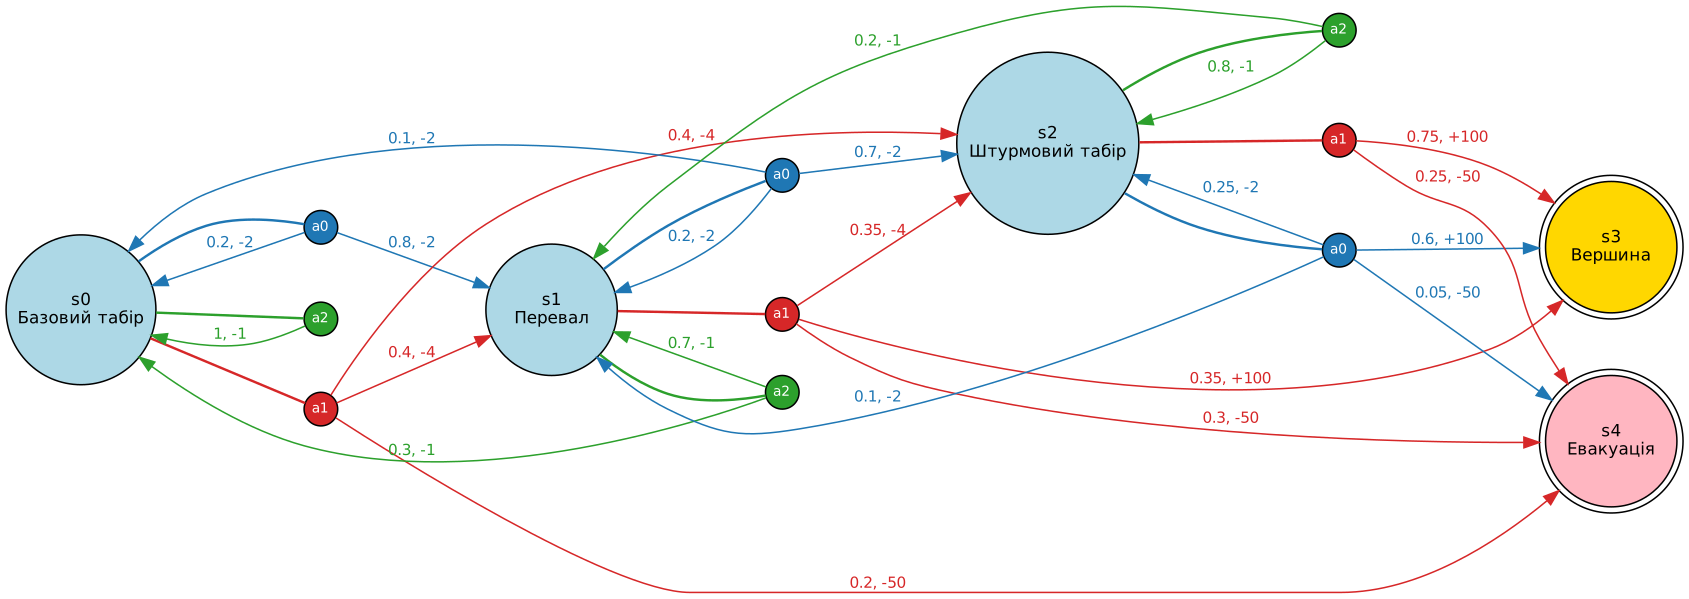

Дії: a0 — обережний підйом (синій), a1 — ривок (червоний), a2 — перечекати (зелений)


In [23]:
import graphviz
from IPython.display import Image, display

def mdp_graph(P, state_names, action_names, terminals, filename="MDP_climb"):
    colors = {0: '#1f77b4', 1: '#d62728', 2: '#2ca02c'}
    g = graphviz.Digraph(filename, format='png', engine='dot')
    g.attr(rankdir='LR', dpi='110', fontname='DejaVu Sans', nodesep='0.35', ranksep='0.9')
    g.attr('node', fontname='DejaVu Sans'); g.attr('edge', fontname='DejaVu Sans', fontsize='10')
    for s, nm in state_names.items():
        fill = '#FFD700' if s == 3 else ('#FFB6C1' if s == 4 else '#ADD8E6')
        g.node(f"s{s}", f"s{s}\n{nm}", shape='doublecircle' if s in terminals else 'circle',
               style='filled', fillcolor=fill, fontsize='11', width='1.2', margin='0.05')
    for s in P:
        if s in terminals: continue
        for a in P[s]:
            an = f"s{s}a{a}"
            g.node(an, f"a{a}", shape='circle', width='0.3', fixedsize='true', style='filled',
                   fillcolor=colors[a], fontcolor='white', fontsize='9')
            g.edge(f"s{s}", an, color=colors[a], arrowhead='none', penwidth='1.6')
            for p, s2, r, d in P[s][a]:
                g.edge(an, f"s{s2}", label=f"{p:g}, {r:+g}", color=colors[a], fontcolor=colors[a])
    with g.subgraph() as sg:
        sg.attr(rank='sink'); sg.node('s3'); sg.node('s4')
    g.save(f"{filename}.dot")
    return g.render(filename, cleanup=True)

png = mdp_graph(P_climb, state_names, action_names, TERMINALS_C)
display(Image(png))
print("Дії: a0 — обережний підйом (синій), a1 — ривок (червоний), a2 — перечекати (зелений)")

## Завдання 2. Політики

* $\pi_1$ — **стохастична** «нетерпляча» політика: у кожному нетермінальному стані дії вибираються випадково, з перевагою ривка в штурмовому таборі:

| стан | $a_0$ обережно | $a_1$ ривок | $a_2$ перечекати |
|---|---|---|---|
| 0 | 0.5 | 0.3 | 0.2 |
| 1 | 0.4 | 0.4 | 0.2 |
| 2 | 0.3 | 0.5 | 0.2 |

* $\pi_2$ — **детермінована** «обережна» політика: завжди $a_0$ (обережний підйом).

**Очікувана відмінність поведінки.** За $\pi_2$ агент піднімається табір за табором, ризикуючи лише в штурмовому таборі ($0.05$ за спробу); епізоди довші, але майже всі закінчуються на вершині. За $\pi_1$ агент часто робить ривки (швидше, але ризиковано) і іноді втрачає дні, перечікуючи або спускаючись, тому результати епізодів сильно розкидані. Для термінальних станів дії не мають значення (задано рівномірний розподіл лише для коректності таблиці політики).

In [24]:
policy1_c = np.array([[0.5, 0.3, 0.2],
                      [0.4, 0.4, 0.2],
                      [0.3, 0.5, 0.2],
                      [1/3, 1/3, 1/3],
                      [1/3, 1/3, 1/3]])
policy2_c_det = np.array([0, 0, 0, 0, 0])
policy2_c = rl.policy_deterministic_to_stochastic(policy2_c_det, nA_c, epsilon=0.0)
print("π1 =\n", policy1_c, "\nπ2 =\n", policy2_c)

π1 =
 [[0.5    0.3    0.2   ]
 [0.4    0.4    0.2   ]
 [0.3    0.5    0.2   ]
 [0.3333 0.3333 0.3333]
 [0.3333 0.3333 0.3333]] 
π2 =
 [[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]


## Завдання 3. Моделювання траєкторій

Приклад однієї траєкторії для кожної політики, далі — $10\,000$ епізодів з лімітом $H=30$ кроків (на практиці епізоди закінчуються значно раніше).

In [25]:
env_c.reset(seed=SEED)
for name, pol in [('π1', policy1_c), ('π2', policy2_c)]:
    G0, steps, traj = rl.run_episode(env_c, pol, GAMMA, max_steps=H_MDP)
    print(f"{name}: " + "  ".join(f"[{s}]-a{a}({r:+d})" for s, a, r, s2, *_ in traj)
          + f"  →  {state_names[traj[-1][3]]}, кроків {steps}, G0={G0:.2f}")

π1: [0]-a1(-4)  [2]-a2(-1)  [2]-a0(+100)  →  Вершина, кроків 3, G0=85.30
π2: [0]-a0(-2)  [1]-a0(-2)  [2]-a0(-2)  [2]-a0(-2)  [1]-a0(-2)  [2]-a0(-2)  [2]-a0(+100)  →  Вершина, кроків 7, G0=62.91


In [26]:
CHECK_STEPS_C = [1, 2, 3, 4, 5, 10, 20, 30]
def climb_outcome(traj):
    return traj[-1][3] if traj[-1][4] else 'limit'

env_c.reset(seed=SEED + 1)
sim_c = {}
for name, pol in [('π1', policy1_c), ('π2', policy2_c)]:
    sim_c[name] = simulate(env_c, pol, GAMMA, N_EPISODES, H_MDP, CHECK_STEPS_C, climb_outcome, nS_c)

print(f"{'':3} | {'вершина':>16} | {'евакуація':>16} | {'ліміт':>7} | {'середній G0':>16} | сер. довжина")
for name in sim_c:
    G, L, O, _ = sim_c[name]
    fs, fe, fl_ = np.mean(O == 3), np.mean(O == 4), np.mean(O == 'limit')
    se = 1.96 * G.std(ddof=1) / np.sqrt(len(G))
    print(f"{name:3} | {fs:.4f} ± {ci(fs, len(O)):.4f} | {fe:.4f} ± {ci(fe, len(O)):.4f} | {fl_:7.4f} | "
          f"{G.mean():7.3f} ± {se:.3f} | {L.mean():.2f}")

    |          вершина |        евакуація |   ліміт |      середній G0 | сер. довжина
π1  | 0.6485 ± 0.0094 | 0.3515 ± 0.0094 |  0.0000 |  35.099 ± 1.225 | 3.63
π2  | 0.9187 ± 0.0054 | 0.0813 ± 0.0054 |  0.0000 |  66.624 ± 0.701 | 4.63


## Завдання 4. Матриці переходів $T^\pi$ і розподіли станів

In [27]:
T1c = rl.compute_transition_matrix(P_climb, policy1_c)
T2c = rl.compute_transition_matrix(P_climb, policy2_c)
print("T^π1 (коректна:", rl.validate_transition_matrix(T1c), ")\n", T1c)
print("\nT^π2 (коректна:", rl.validate_transition_matrix(T2c), ")\n", T2c)

mu0_c = np.zeros(nS_c); mu0_c[0] = 1.0
MU_c = {'π1': distributions(T1c, mu0_c, H_MDP), 'π2': distributions(T2c, mu0_c, H_MDP)}

T^π1 (коректна: True )
 [[0.3   0.52  0.12  0.    0.06 ]
 [0.1   0.22  0.42  0.14  0.12 ]
 [0.    0.07  0.235 0.555 0.14 ]
 [0.    0.    0.    1.    0.   ]
 [0.    0.    0.    0.    1.   ]]

T^π2 (коректна: True )
 [[0.2  0.8  0.   0.   0.  ]
 [0.1  0.2  0.7  0.   0.  ]
 [0.   0.1  0.25 0.6  0.05]
 [0.   0.   0.   1.   0.  ]
 [0.   0.   0.   0.   1.  ]]


In [28]:
for name in MU_c:
    mu_hat = sim_c[name][3]
    print(f"{name}:  k |  розрахунок μ_k (s0..s4)                  |  моделювання                              | max|Δ|")
    for k in CHECK_STEPS_C:
        print(f"     {k:2d} | " + " ".join(f"{x:.4f}" for x in MU_c[name][k]) + "  | "
              + " ".join(f"{x:.4f}" for x in mu_hat[k]) + f"  | {np.abs(mu_hat[k] - MU_c[name][k]).max():.4f}")
    print()

π1:  k |  розрахунок μ_k (s0..s4)                  |  моделювання                              | max|Δ|
      1 | 0.3000 0.5200 0.1200 0.0000 0.0600  | 0.2981 0.5271 0.1191 0.0000 0.0557  | 0.0071
      2 | 0.1420 0.2788 0.2826 0.1394 0.1572  | 0.1442 0.2750 0.2902 0.1369 0.1537  | 0.0076
      3 | 0.0705 0.1550 0.2005 0.3353 0.2387  | 0.0753 0.1573 0.1997 0.3336 0.2341  | 0.0048
      4 | 0.0366 0.0848 0.1207 0.4683 0.2896  | 0.0374 0.0878 0.1245 0.4648 0.2855  | 0.0041
      5 | 0.0195 0.0462 0.0684 0.5471 0.3189  | 0.0188 0.0481 0.0695 0.5508 0.3128  | 0.0061
     10 | 0.0009 0.0022 0.0033 0.6406 0.3530  | 0.0007 0.0026 0.0033 0.6442 0.3492  | 0.0038
     20 | 0.0000 0.0000 0.0000 0.6452 0.3547  | 0.0000 0.0000 0.0000 0.6485 0.3515  | 0.0033
     30 | 0.0000 0.0000 0.0000 0.6453 0.3547  | 0.0000 0.0000 0.0000 0.6485 0.3515  | 0.0032

π2:  k |  розрахунок μ_k (s0..s4)                  |  моделювання                              | max|Δ|
      1 | 0.2000 0.8000 0.0000 0.0000 0.0000  |

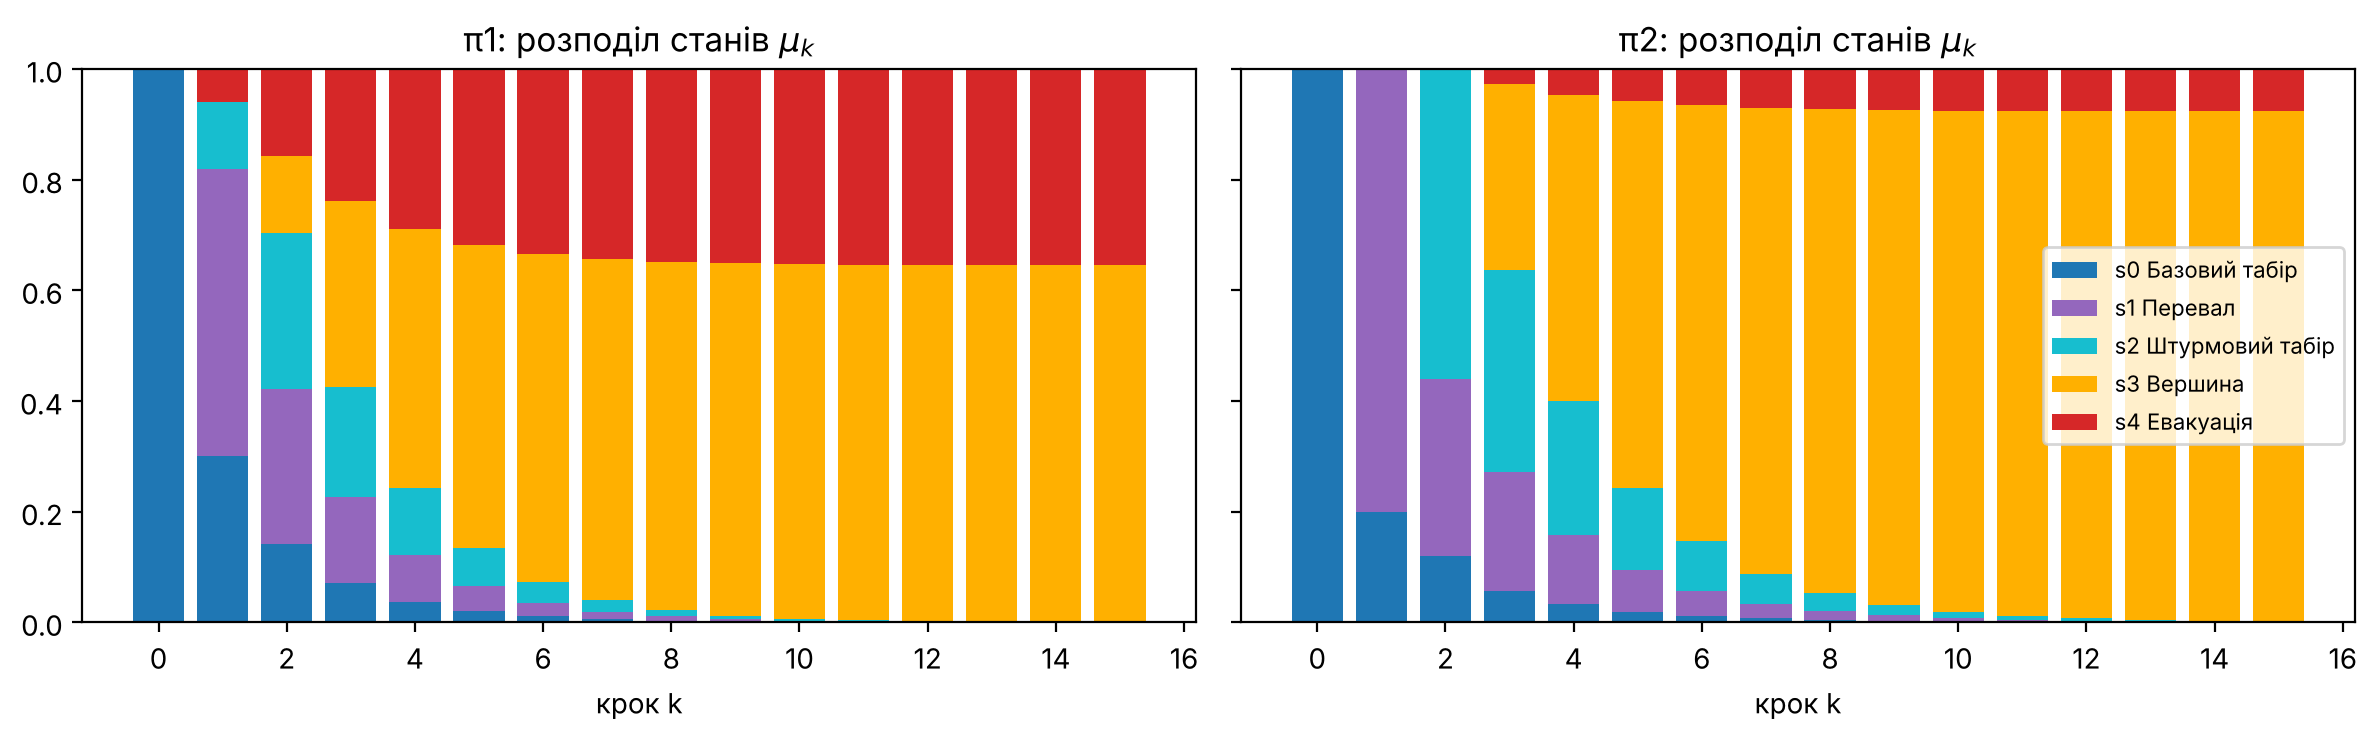

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
cols = ['#1f77b4', '#9467bd', '#17becf', '#FFB000', '#d62728']
for ax, name in zip(axes, MU_c):
    K = 15
    bottom = np.zeros(K + 1)
    for s in range(nS_c):
        ax.bar(range(K + 1), MU_c[name][:K + 1, s], bottom=bottom, color=cols[s], label=f"s{s} {state_names[s]}")
        bottom += MU_c[name][:K + 1, s]
    ax.set_title(f"{name}: розподіл станів $\\mu_k$"); ax.set_xlabel("крок k")
axes[1].legend(fontsize=8, loc='center right'); plt.tight_layout(); plt.show()

Відмінності між політиками видно вже на перших кроках: за $\pi_2$ маса ймовірності «переповзає» $0\to1\to2$, і до кроку 3 евакуація неможлива; за $\pi_1$ вже після першого кроку $\mu_1(4)=0.3\cdot0.2=0.06$ (ривок із базового табору), а з кроку 2 з'являється вершина (ривок із перевалу).

## Завдання 5. Довгострокова поведінка

Середовище має термінальні стани 3 і 4, тому визначаємо ймовірності потрапляння в кожен із них протягом $H=30$ кроків ($\mu_{30}$) і в границі $k\to\infty$ (через $B=(I-Q)^{-1}R$). Окремо перевіримо, чи гарантоване завершення епізоду: чи немає замкненого класу серед нетермінальних станів (тоді $I-Q$ невироджена, а $P(\text{епізод триває після }k\text{ кроків})=\mu_0Q^k\mathbf 1\to0$).

In [30]:
tr_c = [0, 1, 2]
for name, T in [('π1', T1c), ('π2', T2c)]:
    Q = T[np.ix_(tr_c, tr_c)]; R = T[np.ix_(tr_c, TERMINALS_C)]
    B = np.linalg.solve(np.eye(3) - Q, R)
    tau = np.linalg.solve(np.eye(3) - Q, np.ones(3))
    rho = max(abs(np.linalg.eigvals(Q)))
    muH = MU_c[name][H_MDP]
    O = sim_c[name][2]
    print(f"{name}: за H={H_MDP}: P(вершина)={muH[3]:.5f}, P(евакуація)={muH[4]:.5f}, P(триває)={muH[:3].sum():.2e}")
    print(f"     k→∞:   P(вершина)={B[0, 0]:.5f}, P(евакуація)={B[0, 1]:.5f}  (частки моделювання: "
          f"{np.mean(O == 3):.4f} / {np.mean(O == 4):.4f})")
    print(f"     спектральний радіус Q = {rho:.4f} < 1 → завершення гарантоване з імовірністю 1; "
          f"E[тривалість] = {tau[0]:.2f} кроків (моделювання: {sim_c[name][1].mean():.2f})")
    mu_lim, n_it = rl.evolve_distribution(mu0_c, T, theta=1e-12, max_iter=5000)
    print(f"     граничний розподіл (evolve_distribution, {n_it} ітерацій): {mu_lim.round(5)}\n")

π1: за H=30: P(вершина)=0.64526, P(евакуація)=0.35474, P(триває)=3.05e-08
     k→∞:   P(вершина)=0.64526, P(евакуація)=0.35474  (частки моделювання: 0.6485 / 0.3515)
     спектральний радіус Q = 0.5420 < 1 → завершення гарантоване з імовірністю 1; E[тривалість] = 3.61 кроків (моделювання: 3.63)
     граничний розподіл (evolve_distribution, 47 ітерацій): [0.     0.     0.     0.6453 0.3547]

π2: за H=30: P(вершина)=0.92308, P(евакуація)=0.07692, P(триває)=6.94e-07
     k→∞:   P(вершина)=0.92308, P(евакуація)=0.07692  (частки моделювання: 0.9187 / 0.0813)
     спектральний радіус Q = 0.6000 < 1 → завершення гарантоване з імовірністю 1; E[тривалість] = 4.64 кроків (моделювання: 4.63)
     граничний розподіл (evolve_distribution, 56 ітерацій): [0.     0.     0.     0.9231 0.0769]



Завершення епізоду гарантоване для обох політик у тому сенсі, що ймовірність нескінченного епізоду дорівнює нулю (з кожного нетермінального стану є шлях у термінальний). Але тривалість не обмежена зверху: за $\pi_1$ агент може скільки завгодно довго перечікувати або спускатися (з геометрично спадною ймовірністю), а за $\pi_2$ — залишатися у штурмовому таборі через погоду. Як і для FrozenLake, стаціонарний розподіл не єдиний (будь-яка суміш $e_3$ і $e_4$), а граничний розподіл із $s_0$ визначається ймовірностями поглинання.

## Завдання 6. Функція цінності $v_\pi(s)$, $\gamma=0.95$

In [31]:
V_c = {}
for name, pol, T in [('π1', policy1_c, T1c), ('π2', policy2_c, T2c)]:
    r_pi = rl.compute_policy_reward_vector(P_climb, pol)
    v = np.linalg.solve(np.eye(nS_c) - GAMMA * T, r_pi)
    v_it, n_it = rl.policy_evaluation(P_climb, pol, GAMMA, theta=1e-10)
    vH = sum(GAMMA ** t * MU_c[name][t] @ r_pi for t in range(H_MDP))
    G = sim_c[name][0]; se = 1.96 * G.std(ddof=1) / np.sqrt(len(G))
    V_c[name] = v
    print(f"{name}: r_π = {r_pi.round(3)}")
    print(f"     v_π (матрично)  = {v.round(4)}")
    print(f"     v_π (ітераційно)= {v_it.round(4)}  ({n_it} ітерацій)")
    print(f"     v_π(s0) = {v[0]:.3f};  v^(H)(s0) = {vH:.3f};  середній G0 моделювання = {G.mean():.3f} ± {se:.3f}\n")

π1: r_π = [-5.16  6.44 48.09  0.    0.  ]
     v_π (матрично)  = [34.7162 45.5061 65.8077  0.      0.    ]
     v_π (ітераційно)= [34.7162 45.5061 65.8077  0.      0.    ]  (43 ітерацій)
     v_π(s0) = 34.716;  v^(H)(s0) = 34.716;  середній G0 моделювання = 35.099 ± 1.225

π2: r_π = [-2.  -2.  56.8  0.   0. ]
     v_π (матрично)  = [67.0947 74.1405 83.729   0.      0.    ]
     v_π (ітераційно)= [67.0947 74.1405 83.729   0.      0.    ]  (51 ітерацій)
     v_π(s0) = 67.095;  v^(H)(s0) = 67.095;  середній G0 моделювання = 66.624 ± 0.701



In [32]:
# Розкладання v(s0): внесок вершини, евакуації та «вартості днів»
for name, pol, T in [('π1', policy1_c, T1c), ('π2', policy2_c, T2c)]:
    parts = {'вершина (+100)': lambda r: r == 100, 'евакуація (−50)': lambda r: r == -50, 'вартість днів': lambda r: r < 0 and r != -50}
    out = []
    for lbl, cond in parts.items():
        r_part = np.array([sum(pol[s, a] * p * r for a in range(nA_c) for p, s2, r, d in P_climb[s][a] if cond(r))
                           for s in range(nS_c)])
        out.append(f"{lbl}: {np.linalg.solve(np.eye(nS_c) - GAMMA * T, r_part)[0]:+.2f}")
    print(f"{name}: " + ";  ".join(out))

π1: вершина (+100): +55.91;  евакуація (−50): -15.98;  вартість днів: -5.21
π2: вершина (+100): +76.95;  евакуація (−50): -3.21;  вартість днів: -6.65


**Зв'язок цінностей із переходами й винагородами.** Цінність $v_\pi(s)$ зростає з наближенням до вершини ($v(0)<v(1)<v(2)$) для обох політик, бо зі штурмового табору до $+100$ найближче. Розкладання показує, звідки береться різниця у $v_\pi(s_0)$: обережна політика майже не отримує штрафу $-50$ і майже завжди доходить до $+100$; додаткові дні (по $-2$) і дисконтування за довший шлях коштують їй значно менше, ніж ризик евакуації в $\pi_1$. Стохастична $\pi_1$ втрачає цінність і через ризик ривків, і через «порожні» дні з дією $a_2$, які лише відкладають винагороду.

Розрахована $v_\pi(s_0)$ (нескінченний горизонт) практично збігається з $v^{(H)}_\pi(s_0)$, бо за 30 кроків епізоди майже напевно завершуються, і середній $G_0$ потрапляє в довірчий інтервал навколо обох значень.

## Завдання 7. Висновок для власного MDP

In [33]:
for name in sim_c:
    G, L, O, _ = sim_c[name]
    print(f"{name}: v(s0)={V_c[name][0]:.2f}, сер.G0={G.mean():.2f}; P(вершина)={MU_c[name][H_MDP][3]:.3f} "
          f"(частка {np.mean(O==3):.3f}); P(евакуація)={MU_c[name][H_MDP][4]:.3f} (частка {np.mean(O==4):.3f}); "
          f"сер. довжина {L.mean():.2f}")

π1: v(s0)=34.72, сер.G0=35.10; P(вершина)=0.645 (частка 0.648); P(евакуація)=0.355 (частка 0.351); сер. довжина 3.63
π2: v(s0)=67.09, сер.G0=66.62; P(вершина)=0.923 (частка 0.919); P(евакуація)=0.077 (частка 0.081); сер. довжина 4.63


**Висновок (власне MDP «Сходження на вершину»).**

1. **Більшу цінність має детермінована обережна політика $\pi_2$:** $v_{\pi_2}(s_0)\approx67.1$ проти $v_{\pi_1}(s_0)\approx34.7$. Вона ж частіше приводить на вершину ($0.923$ проти $0.645$) і рідше закінчується евакуацією ($0.077$ проти $0.355$).
2. **Поведінка агента.** За $\pi_2$ агент піднімається табір за табором і ризикує лише у штурмовому таборі. Епізоди трохи довші (у середньому 4.6 проти 3.6 кроку), але результати стабільні. Стохастична $\pi_1$ часто робить ривки: це дає швидкі сходження (вершина можлива вже на 2-му кроці), але й ранні евакуації (6 % уже після першого кроку). Крім того, вона витрачає дні на перечікування, тому доходи сильно розкидані.
3. **Зв'язок із моделлю.** Розкладання $v(s_0)$ показує, що різниця між політиками зумовлена передусім ризиком: внесок штрафу $-50$ становить $-16.0$ для $\pi_1$ проти $-3.2$ для $\pi_2$, а внесок вершини — $+55.9$ проти $+77.0$. Більша кількість днів у $\pi_2$ коштує лише $\approx1.4$ одиниці цінності. Завершення епізоду гарантоване з імовірністю 1 для обох політик (спектральний радіус блоку $Q$ менший за 1), хоча тривалість не обмежена зверху. Стаціонарний розподіл не єдиний: граничний розподіл із $s_0$ дорівнює ймовірностям поглинання.
4. **Моделювання узгоджується з розрахунками.** Розподіли станів після $k$ кроків відрізняються від $\mu_0(T^\pi)^k$ не більше ніж на $0.009$. Частки завершень потрапляють у 95 % довірчі інтервали. Середні доходи $35.1\pm1.2$ і $66.6\pm0.7$ узгоджуються з $v_\pi(s_0)$. Тут скінченногоризонтна й нескінченногоризонтна цінності практично збігаються, бо за $H=30$ кроків епізоди завершуються майже напевно (ймовірність продовження менша за $10^{-6}$).

---
# Додаток. Короткі відповіді на контрольні запитання

1. **Модель $P$** містить для кожної пари $(s,a)$ список можливих результатів. Запис `(p, s', r, done)` у `P[s][a]` означає: з імовірністю $p$ після дії $a$ у стані $s$ агент опиниться в $s'$, отримає винагороду $r$, а `done` показує, чи є $s'$ термінальним.
2. **Детермінована політика** задає одну дію в кожному стані, **стохастична** — розподіл дій; $\pi(a\mid s)=\mathbb P(A_t=a\mid S_t=s)$.
3. Випадковість переходів — властивість середовища ($p(s'\mid s,a)$, наприклад ковзання), агент на неї не впливає; випадковий вибір дій — властивість політики агента.
4. $T^\pi_{ss'}=\sum_a\pi(a\mid s)\,p(s'\mid s,a)$. Сума рядка дорівнює 1, бо це сума за $a$ від $\pi(a\mid s)\sum_{s'}p(s'\mid s,a)=\sum_a\pi(a\mid s)=1$.
5. Термінальні стани — поглинальні: $T^\pi_{ss}=1$. Ліміт кроків — це правило зупинки моделювання, а не властивість переходів; марковська матриця не «знає» номера кроку.
6. $\mu_k=\mu_0\,(T^\pi)^k$.
7. Кожен термінальний стан — окремий замкнений клас, тож будь-яка їх суміш стаціонарна. Ймовірності поглинання: $B=(I-Q)^{-1}R$ або $\lim_k\mu_0(T^\pi)^k$.
8. Епізодичне середовище має термінальні стани, продовжуване — ні. Для скінченної траєкторії довжини $H$ обчислюють $G_0^{(H)}=\sum_{t=0}^{H-1}\gamma^tR_{t+1}$; залишок $\le\gamma^H R_{\max}/(1-\gamma)$.
9. $r_\pi(s)$ — очікувана винагорода лише наступного кроку; $v_\pi(s)$ — очікувана сума всіх майбутніх дисконтованих винагород.
10. $v_\pi(s)=\sum_a\pi(a\mid s)\sum_{s',r}p(s',r\mid s,a)[r+\gamma v_\pi(s')]$: цінність = очікувана негайна винагорода + дисконтована цінність наступного стану. У FrozenLake після термінального стану винагород немає, тому $v(G)=v(H)=0$ (винагорода $+1$ нараховується на переході *в* ціль).
11. Матрично: $\mathbf v_\pi=(I-\gamma T^\pi)^{-1}\mathbf r_\pi$. Ітераційно: $\mathbf v_{k+1}=\mathbf r_\pi+\gamma T^\pi\mathbf v_k$; зупинка, коли $\max_s|v_{k+1}(s)-v_k(s)|<\theta$.
12. Імовірність досягнення цілі не враховує часу, а цінність дисконтує пізні успіхи та враховує штрафи. Моделювання дає оцінки зі статистичною похибкою $\sim1/\sqrt n$ і обмежене $H$ кроками, тоді як $v_\pi$ — нескінченногоризонтна величина.